# Trabajo Práctico 2. Visión por Computadora I

Posgrado en Inteligencia Artificial, FIUBA. Docente: Ing. Maxim Dorogov.

Integrantes: Florencia Lucca, Carlos Lugones, Mariano Reimondez.

Consigna:

Objetivo: implementar un detector de máximo enfoque sobre un video aplicando técnicas de análisis espectral similar al que utilizan las cámaras digitales modernas. El video a procesar será `focus_video.mov`.

1. Se debe implementar un algoritmo que dada una imagen, o región, calcule la métrica propuesta en el paper "Image Sharpness Measure for Blurred Images in Frequency Domain" y realizar dos experimentos:
    1. Medición sobre todo el frame.
    2. Medición sobre una ROI ubicada en el centro del frame. Área de la ROI = 5 o 10% del área total del frame.

    Para cada experimento se debe presentar una curva o varias curvas que muestren la evolución de la métrica frame a frame donde se vea claramente cuando el algoritmo detectó la región de máximo enfoque.

El algoritmo de detección a implementar debe detectar y devolver los puntos de máximo enfoque de manera automática.

Puntos extra: aplicar unsharp masking para expandir la zona de enfoque y devolver.

| Pedido de la consigna | Sección |
|---|---|
| Algoritmo que calcule la métrica del paper sobre una imagen o región | 1 |
| Detección y devolución automática de la región de máximo enfoque | 2 y 8 |
| Experimento 1: medición sobre todo el frame | 3 |
| Experimento 2: medición sobre una ROI central del 5% y del 10% | 4 |
| Curvas frame a frame con la región detectada | 3, 4 y 6 |
| Complemento: matriz de enfoque, como en el ejemplo del enunciado | 5 |
| Puntos extra: unsharp masking en la zona de frontera | 7 |

In [1]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

# ruta del video: carpeta TP2 del repositorio o, en Colab, el archivo subido a /content
CANDIDATOS = [Path("video") / "focus_video.mov", Path("focus_video.mov"), Path("/content/focus_video.mov")]
VIDEO = next((p for p in CANDIDATOS if p.exists()), CANDIDATOS[0])
FIGURAS = Path("figuras")
SALIDAS = Path("salidas")
FIGURAS.mkdir(exist_ok=True)
SALIDAS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 72   # resolución en pantalla; las figuras en disco se guardan a 100 dpi


def leer_video(ruta):
    # VideoCapture no falla si el archivo no existe: hay que verificarlo con isOpened
    cap = cv2.VideoCapture(str(ruta))
    if not cap.isOpened():
        raise FileNotFoundError(f"No se pudo abrir {ruta}. Ejecutar el notebook desde la carpeta TP2 o, en Colab, subir el video a /content.")
    fps = cap.get(cv2.CAP_PROP_FPS)
    frames = []
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        frames.append(frame)
    cap.release()
    return frames, fps


frames_bgr, FPS = leer_video(VIDEO)
grises = [cv2.cvtColor(f, cv2.COLOR_BGR2GRAY) for f in frames_bgr]
N = len(grises)
ALTO, ANCHO = grises[0].shape
print(f"{N} frames de {ANCHO} x {ALTO} píxeles a {FPS:.2f} fps ({N / FPS:.1f} s)")

171 frames de 640 x 360 píxeles a 29.97 fps (5.7 s)


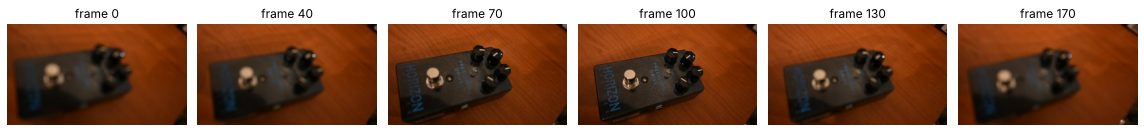

In [2]:
muestra = [0, 40, 70, 100, 130, N - 1]
fig, ax = plt.subplots(1, len(muestra), figsize=(16, 2.4))
for a, i in zip(ax, muestra):
    a.imshow(cv2.cvtColor(frames_bgr[i], cv2.COLOR_BGR2RGB))
    a.set_title(f"frame {i}")
    a.axis("off")
fig.tight_layout()
fig.savefig(FIGURAS / "frames_muestra.png", dpi=100, bbox_inches="tight")
plt.show()

**Figura 1.** Seis frames del video original, del 0 al 170. El pedal arranca desenfocado, pasa por el foco cerca de la mitad del video y vuelve a desenfocarse hacia el final. Es el recorrido que la curva de la métrica tiene que reflejar.

El video es un pedal de efectos fotografiado de cerca con poca profundidad de campo. Arranca desenfocado, el foco pasa por el pedal y vuelve a desenfocarse hacia el final. Por eso se espera una curva que empiece baja, suba hasta una meseta y vuelva a bajar.

## 1. Métrica de enfoque en el dominio de la frecuencia

El paper de De y Masilamani (2013) propone la medida FM (Frequency domain image blur Measure):

1. Calcular la transformada de Fourier $F$ de la imagen $I$ de tamaño $M \times N$.
2. Centrar el origen de frecuencias ($F_c$, equivalente a `fftshift`).
3. Calcular el módulo $AF = |F_c|$.
4. Obtener $M_{max} = \max(AF)$, que en la práctica es la componente de continua (el brillo medio).
5. Contar $T_H$, la cantidad de componentes con $AF > M_{max}/1000$.
6. $FM = T_H / (M \cdot N)$.

La idea es la vista en clase sobre filtros: el desenfoque actúa como un pasabajos, atenúa las altas frecuencias y hace caer muchas componentes por debajo del umbral, que es relativo a la componente de continua. FM es entonces la fracción del espectro con energía significativa. En el paper la letra M se usa tanto para el máximo como para el alto de la imagen; acá se los distingue para evitar confusiones.

In [3]:
def fm(imagen):
    # Medida de enfoque FM (De y Masilamani, 2013) sobre una imagen o región en escala de grises
    img = np.asarray(imagen, dtype=np.float64)
    af = np.abs(np.fft.fftshift(np.fft.fft2(img)))   # pasos 1 a 3
    m_max = af.max()                                # paso 4
    th = np.count_nonzero(af > m_max / 1000)        # paso 5
    return th / img.size                            # paso 6

### Validación de la implementación

Antes de aplicarla al video verificamos que la métrica se comporte como se espera. Si desenfocamos un frame nítido con filtros gaussianos de sigma creciente, FM tiene que bajar en forma monótona. Mostramos también los espectros con la máscara de componentes que superan el umbral.

In [4]:
REF = 100   # frame nítido a simple vista
sigmas = [0, 0.5, 1, 1.5, 2, 3, 4, 6]
fm_blur = [fm(grises[REF] if s == 0 else cv2.GaussianBlur(grises[REF], (0, 0), s)) for s in sigmas]
for s, v in zip(sigmas, fm_blur):
    print(f"sigma = {s:<4} FM = {v:.4f}")
print("¿Monótonamente decreciente?", bool(np.all(np.diff(fm_blur) < 0)))

sigma = 0    FM = 0.0271
sigma = 0.5  FM = 0.0251
sigma = 1    FM = 0.0202
sigma = 1.5  FM = 0.0169
sigma = 2    FM = 0.0143
sigma = 3    FM = 0.0103
sigma = 4    FM = 0.0083
sigma = 6    FM = 0.0059
¿Monótonamente decreciente? True


**Tabla 1.** FM del frame 100 desenfocado con filtros gaussianos de sigma creciente. La métrica baja en cada paso, que es lo que esperamos de una medida de enfoque.

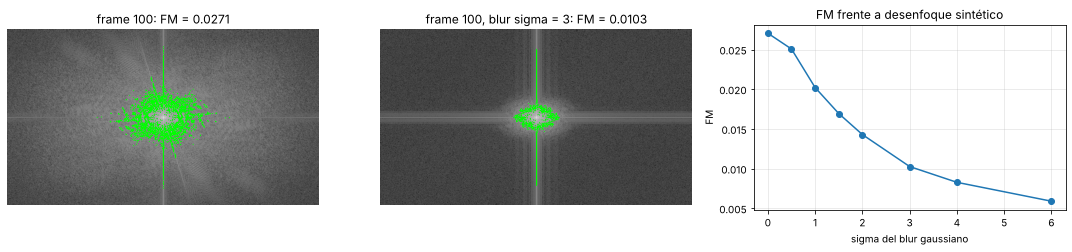

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, (titulo, img) in zip(ax[:2], (("frame 100", grises[REF]), ("frame 100, blur sigma = 3", cv2.GaussianBlur(grises[REF], (0, 0), 3)))):
    af = np.abs(np.fft.fftshift(np.fft.fft2(img.astype(np.float64))))
    mascara = af > af.max() / 1000
    a.imshow(np.log1p(af), cmap="gray")
    a.contour(mascara, levels=[0.5], colors="lime", linewidths=0.6)
    a.set_title(f"{titulo}: FM = {fm(img):.4f}")
    a.axis("off")
ax[2].plot(sigmas, fm_blur, "o-")
ax[2].set_xlabel("sigma del blur gaussiano")
ax[2].set_ylabel("FM")
ax[2].set_title("FM frente a desenfoque sintético")
ax[2].grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURAS / "validacion_fm.png", dpi=100, bbox_inches="tight")
plt.show()

**Figura 2.** A la izquierda y al centro, espectros de magnitud en escala logarítmica del frame 100 nítido y del mismo frame con desenfoque gaussiano de sigma 3. El contorno verde delimita las componentes que superan el umbral de la métrica. A la derecha, FM en función de sigma. Al desenfocar, la zona verde se achica hacia el centro y FM cae.

FM baja de 0,0271 a 0,0059 cuando sigma pasa de 0 a 6, y lo hace en forma monótona (Tabla 1). El paper reporta 0,0182 para Lena nítida y 0,0045 desenfocada, así que el orden de magnitud coincide. En los espectros de la Figura 2 se ve la diferencia: en el frame nítido la máscara de componentes por encima del umbral (en verde) llega mucho más lejos del centro que en el desenfocado. Esa pérdida de altas frecuencias es justamente lo que mide el indicador.

Las líneas horizontal y vertical que cruzan el origen no son contenido de la escena. Aparecen porque la DFT trata la imagen como periódica y los bordes opuestos del frame no coinciden. Como están en los dos casos y no alteran la tendencia, mantuvimos la métrica tal como la define el paper, sin ventaneo.

## 2. Detección automática de la región de máximo enfoque

La consigna pide detectar una región y no un frame. Quedarse con el frame que maximiza la métrica no alcanza, porque alrededor de ese punto hay varios frames que a simple vista están igual de enfocados. El algoritmo que proponemos tiene cuatro pasos:

1. Suavizar la curva con una media móvil de 5 frames (un filtro pasabajos 1D, el mismo concepto que los filtros de caja vistos en clase) para que un frame aislado con ruido de compresión no corte la región.
2. Normalizar la curva suavizada entre su mínimo y su máximo. Así el umbral queda expresado como fracción del rango dinámico de la métrica y no depende de su escala, que cambia mucho entre el frame completo y una ROI.
3. Tomar como pico el máximo de la curva suavizada.
4. Expandir hacia ambos lados desde el pico mientras la curva normalizada se mantenga en o por encima del umbral (0,8). La región es el intervalo contiguo que contiene al pico.

La función devuelve los frames de inicio, pico y fin, y sus tiempos en segundos.

In [6]:
UMBRAL = 0.8
VENTANA = 5


def suavizar(v, k=VENTANA):
    v = np.asarray(v, dtype=np.float64)
    return np.convolve(np.pad(v, k // 2, mode="edge"), np.ones(k) / k, mode="valid")


def detectar_region(v, umbral=UMBRAL, rango=None, fps=None):
    fps = FPS if fps is None else fps
    # rango=(min, max) permite normalizar con una escala fija (se usa en el punto extra)
    s = suavizar(v)
    lo, hi = rango if rango is not None else (s.min(), s.max())
    n = (s - lo) / (hi - lo)
    pico = int(np.argmax(s))   # si hubiera empates, argmax toma el primero; en este video el máximo es único
    ini = fin = pico
    while ini > 0 and n[ini - 1] >= umbral:
        ini -= 1
    while fin < len(n) - 1 and n[fin + 1] >= umbral:
        fin += 1
    return {"inicio": ini, "pico": pico, "fin": fin, "t_inicio": ini / fps, "t_pico": pico / fps,
            "t_fin": fin / fps, "suavizada": s, "normalizada": n, "rango": (lo, hi)}


def graficar_curva(ax, v, r, titulo, color="tab:blue"):
    ax.plot(v, ".", ms=4, color=color, alpha=0.6, label="FM por frame")
    ax.plot(r["suavizada"], color=color, lw=1.6, label="media móvil (5 frames)")
    ax.axvspan(r["inicio"], r["fin"], color="tab:green", alpha=0.18, label="región de máximo enfoque")
    ax.axvline(r["pico"], color="tab:red", ls="--", lw=1, label=f"pico (frame {r['pico']})")
    lo, hi = r["rango"]
    ax.axhline(lo + UMBRAL * (hi - lo), color="gray", ls=":", lw=1, label=f"umbral ({UMBRAL:.0%} del rango)")
    ax.set_title(f"{titulo}: frames {r['inicio']} a {r['fin']} ({r['t_inicio']:.2f} a {r['t_fin']:.2f} s)")
    ax.set_xlabel("frame")
    ax.set_ylabel("FM")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="upper left")


def resumen(nombre, r):
    print(f"{nombre:<16} inicio {r['inicio']:>3}  pico {r['pico']:>3}  fin {r['fin']:>3}  "
          f"({r['fin'] - r['inicio'] + 1} frames, {r['t_inicio']:.2f} a {r['t_fin']:.2f} s)")

## 3. Experimento 1: medición sobre todo el frame

frame completo   inicio  76  pico 109  fin 116  (41 frames, 2.54 a 3.87 s)


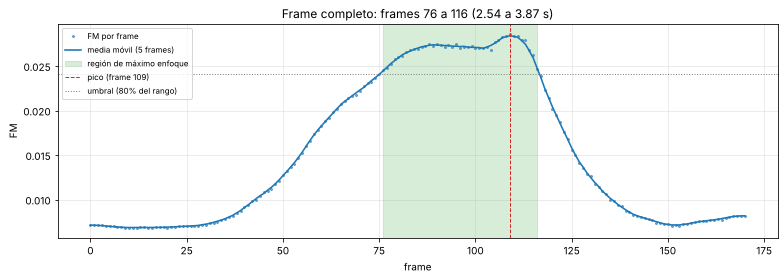

In [7]:
fm_completo = np.array([fm(g) for g in grises])
r_completo = detectar_region(fm_completo)
resumen("frame completo", r_completo)

fig, ax = plt.subplots(figsize=(11, 4))
graficar_curva(ax, fm_completo, r_completo, "Frame completo")
fig.tight_layout()
fig.savefig(FIGURAS / "exp1_frame_completo.png", dpi=100, bbox_inches="tight")
plt.show()

**Figura 3.** Evolución de FM sobre el frame completo. Los puntos son los valores de cada frame y la línea continua, la media móvil de 5 frames. En verde se marca la región de máximo enfoque detectada en forma automática (frames 76 a 116) y la línea roja indica el pico (frame 109).

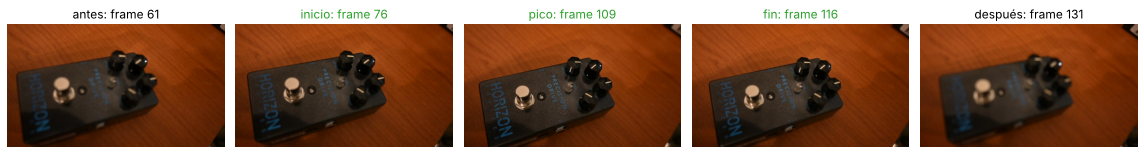

In [8]:
def mostrar_frames(r, recorte=None, nombre=None):
    # frames antes de la región, inicio, pico, fin y después
    idx = [max(r["inicio"] - 15, 0), r["inicio"], r["pico"], r["fin"], min(r["fin"] + 15, N - 1)]
    etiquetas = ["antes", "inicio", "pico", "fin", "después"]
    fig, ax = plt.subplots(1, 5, figsize=(16, 2.6 if recorte is None else 2.9))
    for a, i, e in zip(ax, idx, etiquetas):
        img = cv2.cvtColor(frames_bgr[i], cv2.COLOR_BGR2RGB)
        if recorte is not None:
            y0, y1, x0, x1 = recorte
            img = img[y0:y1, x0:x1]
        a.imshow(img)
        a.set_title(f"{e}: frame {i}", color="tab:green" if r["inicio"] <= i <= r["fin"] else "black")
        a.axis("off")
    fig.tight_layout()
    if nombre:
        fig.savefig(FIGURAS / nombre, dpi=100, bbox_inches="tight")
    plt.show()


mostrar_frames(r_completo, nombre="exp1_frames.png")

**Figura 4.** Frames antes, al inicio, en el pico, al final y después de la región detectada con el frame completo. Los títulos en verde corresponden a frames dentro de la región. Se ve el contraste entre los extremos borrosos y los tres frames centrales.

En el frame completo (Figura 3) la métrica va de 0,0068 a 0,0286, un rango de 4,2 veces. La región detectada abarca los frames 76 a 116 (2,54 a 3,87 s), con el pico en el 109. La curva sube despacio entre los frames 40 y 80 y cae mucho más rápido después del 116. Dicho de otro modo, el foco se gana de a poco y se pierde en pocos frames. En la Figura 4 el frame del pico es el más nítido. El del inicio (76) ya deja leer el texto del pedal pero todavía está algo blando, porque con el frame completo la región empieza antes que con la ROI. Los frames tomados 15 antes y 15 después de la región están claramente borrosos.

Es la región más ancha de todos los experimentos y la de menor rango dinámico. Con el frame completo la métrica integra zonas a distintas profundidades (la mesa, el pedal, las perillas), y en casi cualquier frame hay alguna parte de la escena cerca del foco. A eso se suma la madera del fondo: tiene poca textura, aporta pocas altas frecuencias en todos los frames y diluye la diferencia entre enfocado y desenfocado.

## 4. Experimento 2: medición sobre una ROI central

La ROI es un rectángulo centrado con la misma relación de aspecto que el frame, de modo que su área sea exactamente la fracción pedida. Evaluamos las dos opciones de la consigna, 5% y 10%.

ROI 5%: 143 x 80 px = 4.97% del frame
ROI 5%           inicio  89  pico 111  fin 114  (26 frames, 2.97 a 3.80 s)
ROI 10%: 202 x 114 px = 9.99% del frame
ROI 10%          inicio  90  pico 111  fin 114  (25 frames, 3.00 a 3.80 s)


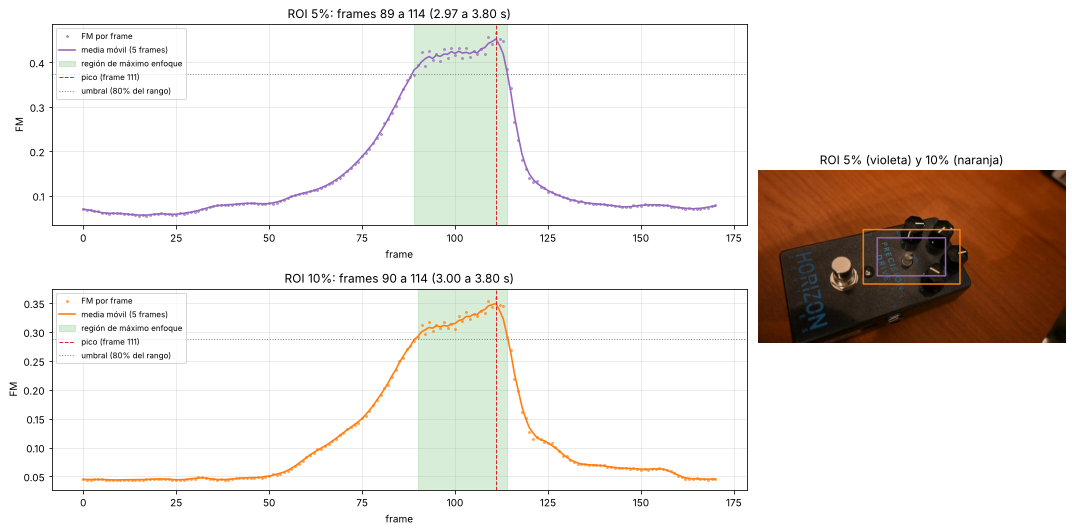

In [9]:
def roi_central(frac, alto=ALTO, ancho=ANCHO):
    # devuelve (y0, y1, x0, x1) de un rectángulo centrado con área = frac * área del frame
    h = int(round(alto * np.sqrt(frac)))
    w = int(round(ancho * np.sqrt(frac)))
    y0, x0 = (alto - h) // 2, (ancho - w) // 2
    return y0, y0 + h, x0, x0 + w


rois, fm_roi, r_roi = {}, {}, {}
for frac in (0.05, 0.10):
    y0, y1, x0, x1 = rois[frac] = roi_central(frac)
    fm_roi[frac] = np.array([fm(g[y0:y1, x0:x1]) for g in grises])
    r_roi[frac] = detectar_region(fm_roi[frac])
    print(f"ROI {frac:.0%}: {x1 - x0} x {y1 - y0} px = {(x1 - x0) * (y1 - y0) / (ALTO * ANCHO):.2%} del frame")
    resumen(f"ROI {frac:.0%}", r_roi[frac])

fig = plt.figure(figsize=(15, 7.5))
g = fig.add_gridspec(2, 3, width_ratios=[1, 1, 0.9])
for k, (frac, color) in enumerate(((0.05, "tab:purple"), (0.10, "tab:orange"))):
    graficar_curva(fig.add_subplot(g[k, :2]), fm_roi[frac], r_roi[frac], f"ROI {frac:.0%}", color=color)
a = fig.add_subplot(g[:, 2])
vis = cv2.cvtColor(frames_bgr[r_roi[0.10]["pico"]], cv2.COLOR_BGR2RGB).copy()
for frac, color in ((0.05, (148, 103, 189)), (0.10, (255, 127, 14))):
    y0, y1, x0, x1 = rois[frac]
    cv2.rectangle(vis, (x0, y0), (x1 - 1, y1 - 1), color, 2)
a.imshow(vis)
a.set_title("ROI 5% (violeta) y 10% (naranja)")
a.axis("off")
fig.tight_layout()
fig.savefig(FIGURAS / "exp2_roi.png", dpi=100, bbox_inches="tight")
plt.show()

**Figura 5.** Curvas de FM para la ROI central del 5% (arriba) y del 10% (abajo), con la región detectada en verde. A la derecha, la ubicación de las dos ROI sobre el frame del pico: las dos quedan sobre el texto y las perillas del pedal.

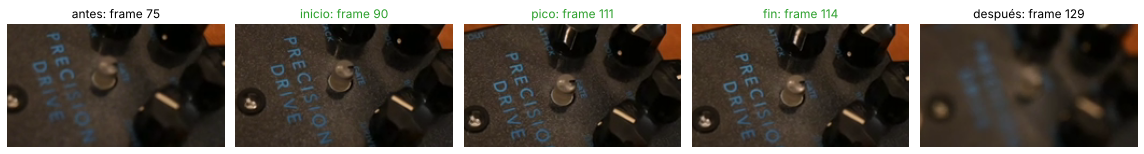

In [10]:
mostrar_frames(r_roi[0.10], recorte=rois[0.10], nombre="exp2_frames_roi10.png")

**Figura 6.** Los mismos cinco momentos de la Figura 4, ahora recortados a la ROI del 10%. En el recorte, la diferencia entre los frames de adentro y de afuera de la región es más evidente que en el frame completo.

Las dos ROI dan casi lo mismo (Figura 5): frames 89 a 114 con la del 5% y 90 a 114 con la del 10%, las dos con pico en el frame 111. El tamaño de la ROI, entonces, no cambia el resultado. El rango dinámico se duplica respecto del frame completo (8,5 y 8,4 veces). La razón es que la ROI cae sobre el texto "PRECISION DRIVE" y las perillas, con mucho detalle fino y a una profundidad parecida, y deja afuera la mesa.

Dentro de la región la curva no es plana: hay una meseta entre los frames 90 y 105 y el máximo está en el 111. Después del 114 la caída es abrupta. En el frame 118 la métrica ya está muy por debajo del umbral. En los recortes de la Figura 6 el contraste entre los frames de adentro y de afuera de la región es más marcado que en el frame completo.

### Elección del umbral y verificación visual

No elegimos el umbral de 0,8 por la región que produce, sino comparando con lo que se ve. Lo contrastamos con el criterio sugerido en clase (todo lo que esté dentro del 10% del máximo de la métrica, sin normalizar) y con otros umbrales, y revisamos los recortes de la ROI del 10% a resolución completa.

In [11]:
curvas = {"frame completo": fm_completo, "ROI 5%": fm_roi[0.05], "ROI 10%": fm_roi[0.10]}
print(f"{'criterio':<28}" + "".join(f"{k:>18}" for k in curvas))
for u in (0.7, 0.75, 0.8, 0.85, 0.9):
    fila = [detectar_region(v, umbral=u) for v in curvas.values()]
    print(f"{'normalizado ' + str(u):<28}" + "".join(f"{str(r['inicio']) + ' a ' + str(r['fin']):>18}" for r in fila))
fila = []
for v in curvas.values():
    s = suavizar(v)
    fila.append(detectar_region(v, umbral=0.9, rango=(0, s.max())))
print(f"{'FM >= 90% del máximo':<28}" + "".join(f"{str(r['inicio']) + ' a ' + str(r['fin']):>18}" for r in fila))

criterio                        frame completo            ROI 5%           ROI 10%
normalizado 0.7                       69 a 118          86 a 114          87 a 115
normalizado 0.75                      73 a 117          88 a 114          88 a 114
normalizado 0.8                       76 a 116          89 a 114          90 a 114
normalizado 0.85                      78 a 115          91 a 113          92 a 113
normalizado 0.9                       81 a 114          95 a 113         101 a 113
FM >= 90% del máximo                  79 a 115          92 a 113         100 a 113


**Tabla 2.** Región detectada (frame inicial a frame final) con distintos umbrales sobre la curva normalizada y con el criterio sugerido en clase, que exige una FM de al menos el 90% del máximo. Entre 0,7 y 0,85 el inicio de la región de las ROI se mueve hasta 5 frames y el final, hasta 2. El criterio del 90% del máximo recorta la región por la izquierda, sobre todo en la ROI del 10%.

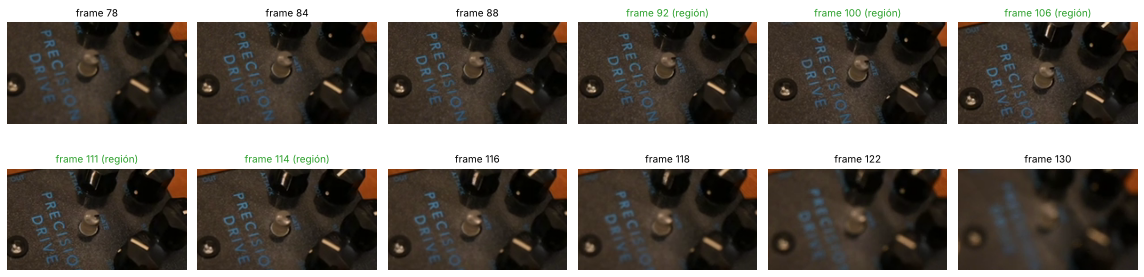

In [12]:
y0, y1, x0, x1 = rois[0.10]
idx = [78, 84, 88, 92, 100, 106, 111, 114, 116, 118, 122, 130]
fig, ax = plt.subplots(2, 6, figsize=(16, 4.6))
for a, i in zip(ax.ravel(), idx):
    dentro = r_roi[0.10]["inicio"] <= i <= r_roi[0.10]["fin"]
    a.imshow(cv2.cvtColor(frames_bgr[i][y0:y1, x0:x1], cv2.COLOR_BGR2RGB))
    a.set_title(f"frame {i}" + (" (región)" if dentro else ""), color="tab:green" if dentro else "black", fontsize=10)
    a.axis("off")
fig.tight_layout()
fig.savefig(FIGURAS / "verificacion_visual_roi10.png", dpi=100, bbox_inches="tight")
plt.show()

**Figura 7.** Recortes de la ROI del 10% a resolución completa en doce frames alrededor de la región. Los títulos en verde marcan los frames que el detector incluye. Sobre esta figura hicimos la verificación visual del umbral que se discute a continuación.

Con el criterio sugerido en clase (FM de al menos el 90% del máximo), la ROI del 10% queda entre los frames 100 y 113 (Tabla 2). Es una región más angosta que la nuestra y deja afuera la meseta 90 a 99. Sin embargo, en los recortes de la Figura 7 los frames 92 y 100 se ven tan nítidos como el 106 o el 111: las letras de "PRECISION DRIVE" y los bordes de las perillas están igual de definidos. El frame 78 está claramente blando y el 84 y el 88 están en el límite. Hacia el otro lado, el 116 empieza a perder definición y del 118 en adelante el desenfoque es evidente. El umbral de 0,8 sobre la curva normalizada delimita 90 a 114, que coincide con lo que se ve.

La Tabla 2 muestra además que la detección es estable. Entre 0,7 y 0,85 el inicio de la región de las ROI se mueve hasta 5 frames y el final, hasta 2. Recién con 0,9 se pierde buena parte de la meseta. Normalizar tiene otra ventaja. El criterio sobre el máximo sin normalizar depende del piso de la métrica, que no es cero y cambia entre experimentos (0,0068 en el frame completo, 0,043 en la ROI del 10%). La fracción del rango dinámico, en cambio, significa lo mismo en todos los casos.

## 5. Matriz de enfoque

En la diapositiva del enunciado, la curva de referencia no se calcula sobre el frame completo ni sobre una única ROI. Se usa una matriz de enfoque: una grilla de regiones sobre la zona central del frame, con la métrica calculada en cada una y luego promediada. Es lo que hacen las cámaras con varios puntos de enfoque. Además de la curva promedio, la matriz permite ver en qué parte de la escena está el foco en cada frame.

Usamos una grilla de 7 x 7 celdas que cubre el 50% central del ancho y del alto del frame.

celdas de 45 x 25 px
matriz 7 x 7     inicio  84  pico  99  fin 114  (31 frames, 2.80 a 3.80 s)


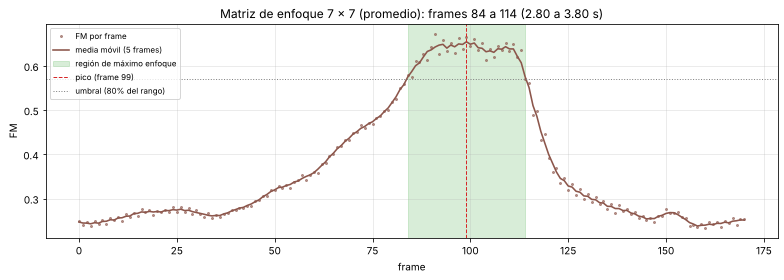

In [13]:
FILAS = COLS = 7
MY0, MY1 = ALTO // 4, 3 * ALTO // 4
MX0, MX1 = ANCHO // 4, 3 * ANCHO // 4
ys = np.linspace(MY0, MY1, FILAS + 1).astype(int)
xs = np.linspace(MX0, MX1, COLS + 1).astype(int)


def matriz_enfoque(gris):
    return np.array([[fm(gris[ys[i]:ys[i + 1], xs[j]:xs[j + 1]]) for j in range(COLS)] for i in range(FILAS)])


matrices = np.array([matriz_enfoque(g) for g in grises])
fm_matriz = matrices.mean(axis=(1, 2))
r_matriz = detectar_region(fm_matriz)
print(f"celdas de {xs[1] - xs[0]} x {ys[1] - ys[0]} px")
resumen("matriz 7 x 7", r_matriz)

fig, ax = plt.subplots(figsize=(11, 4))
graficar_curva(ax, fm_matriz, r_matriz, "Matriz de enfoque 7 x 7 (promedio)", color="tab:brown")
fig.tight_layout()
fig.savefig(FIGURAS / "matriz_curva.png", dpi=100, bbox_inches="tight")
plt.show()

**Figura 8.** Curva promedio de la matriz de enfoque de 7 x 7 celdas, con la región detectada (frames 84 a 114) y el pico en el frame 99. Es la curva equivalente a la de referencia que muestra el enunciado.

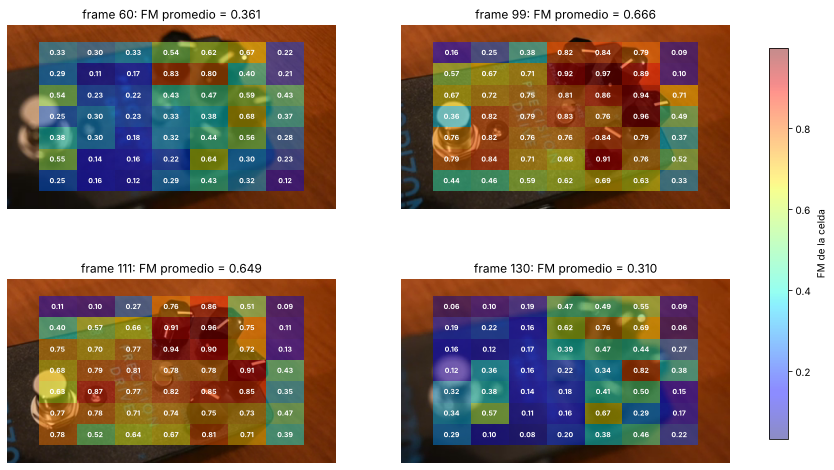

In [14]:
# matriz superpuesta como mapa de calor, con el valor de FM de cada celda
vmin, vmax = matrices.min(), matrices.max()
sel = [60, r_matriz["pico"], r_roi[0.10]["pico"], 130]
mx, my = int(0.12 * (MX1 - MX0)), int(0.12 * (MY1 - MY0))
fig, ax = plt.subplots(2, 2, figsize=(14, 8.4))
for a, t in zip(ax.ravel(), sel):
    a.imshow(cv2.cvtColor(frames_bgr[t], cv2.COLOR_BGR2RGB))
    im = a.imshow(matrices[t], extent=(MX0, MX1, MY1, MY0), cmap="jet", alpha=0.45, vmin=vmin, vmax=vmax)
    for i in range(FILAS):
        for j in range(COLS):
            a.text((xs[j] + xs[j + 1]) / 2, (ys[i] + ys[i + 1]) / 2, f"{matrices[t, i, j]:.2f}",
                   ha="center", va="center", color="white", fontsize=7, fontweight="bold")
    a.set_xlim(MX0 - mx, MX1 + mx)
    a.set_ylim(MY1 + my, MY0 - my)
    a.set_title(f"frame {t}: FM promedio = {matrices[t].mean():.3f}")
    a.axis("off")
fig.colorbar(im, ax=ax, fraction=0.025, label="FM de la celda")
fig.savefig(FIGURAS / "matriz_superpuesta.png", dpi=100, bbox_inches="tight")
plt.show()

**Figura 9.** Mapa de calor de FM por celda superpuesto a cuatro frames: antes del foco (60), en el pico de la matriz (99), en el pico de la ROI central (111) y después del foco (130). Cada celda muestra su valor de FM, y el color usa la misma escala en los cuatro casos.

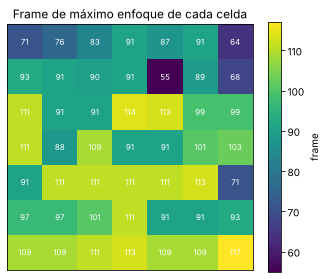

In [15]:
# frame de máximo enfoque de cada celda: muestra cómo se desplaza el plano de foco por la escena
pico_celda = matrices.argmax(axis=0)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(pico_celda, cmap="viridis")
for i in range(FILAS):
    for j in range(COLS):
        ax.text(j, i, pico_celda[i, j], ha="center", va="center", color="w", fontsize=8)
ax.set_title("Frame de máximo enfoque de cada celda")
ax.set_xticks([])
ax.set_yticks([])
fig.colorbar(im, ax=ax, label="frame")
fig.savefig(FIGURAS / "matriz_pico_por_celda.png", dpi=100, bbox_inches="tight")
plt.show()

**Figura 10.** Frame en el que cada celda de la matriz alcanza su máximo de FM. Las celdas de la fila superior llegan antes que las del cuerpo del pedal, lo que muestra el recorrido del plano de foco por la escena.

La curva promedio de la matriz (Figura 8) tiene el pico en el frame 99 y la región entre los frames 84 y 114. Tiene la misma forma que la curva de referencia de la diapositiva, que también marca el máximo alrededor del frame 95. El rango dinámico es menor (2,9 veces) porque las celdas son chicas, de 45 x 25 píxeles, y varias caen sobre zonas lisas donde la métrica depende más del ruido que del foco.

Lo más interesante es el mapa del frame de máximo enfoque por celda (Figura 10). Las celdas del centro y de la parte inferior, sobre el cuerpo del pedal, llegan a su máximo entre los frames 109 y 113, igual que la ROI central. Las de la fila superior llegan antes, entre el 71 y el 91. Las distintas zonas de la escena están a distintas distancias de la cámara, así que el plano de foco las atraviesa en distintos momentos y la matriz lo registra. Por eso su pico promedio (99) queda entre los de las distintas zonas, mientras que la ROI central mide solo el objeto del centro. Las pocas celdas con valores aislados (55, 64) están sobre zonas casi sin textura, donde el máximo no es representativo.

El mapa de calor superpuesto de la Figura 9 muestra el mismo recorrido. En el frame 60 los valores altos están solo arriba a la derecha, en los frames 99 y 111 se extienden a casi todo el pedal y en el frame 130 la mayoría de las celdas vuelve a valores bajos.

## 6. Comparación de los experimentos

Como las escalas son muy distintas, para comparar las curvas las graficamos normalizadas entre su mínimo y su máximo.

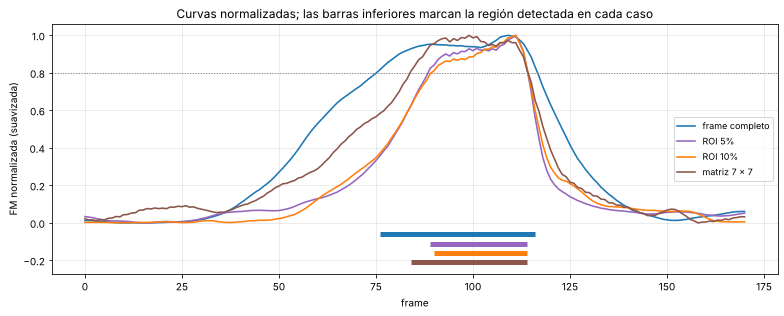

In [16]:
todas = {"frame completo": (fm_completo, r_completo, "tab:blue"), "ROI 5%": (fm_roi[0.05], r_roi[0.05], "tab:purple"),
         "ROI 10%": (fm_roi[0.10], r_roi[0.10], "tab:orange"), "matriz 7 x 7": (fm_matriz, r_matriz, "tab:brown")}
fig, ax = plt.subplots(figsize=(11, 4.5))
for k, (nombre, (v, r, color)) in enumerate(todas.items()):
    ax.plot(r["normalizada"], color=color, lw=1.6, label=nombre)
    ax.plot([r["inicio"], r["fin"]], [-0.06 - 0.05 * k] * 2, color=color, lw=5, solid_capstyle="butt")
ax.axhline(UMBRAL, color="gray", ls=":", lw=1)
ax.set_xlabel("frame")
ax.set_ylabel("FM normalizada (suavizada)")
ax.set_title("Curvas normalizadas; las barras inferiores marcan la región detectada en cada caso")
ax.grid(alpha=0.3)
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(FIGURAS / "comparacion.png", dpi=100, bbox_inches="tight")
plt.show()

**Figura 11.** Curvas suavizadas y normalizadas de los cuatro experimentos, superpuestas. Las barras inferiores marcan la región detectada en cada caso: todas terminan entre los frames 114 y 116, pero empiezan antes cuanto más grande es el área medida.

In [17]:
print(f"{'experimento':<16}{'inicio':>8}{'pico':>6}{'fin':>6}{'frames':>8}{'FM mín':>10}{'FM máx':>10}{'máx/mín':>9}")
for nombre, (v, r, _) in todas.items():
    print(f"{nombre:<16}{r['inicio']:>8}{r['pico']:>6}{r['fin']:>6}{r['fin'] - r['inicio'] + 1:>8}"
          f"{v.min():>10.4f}{v.max():>10.4f}{v.max() / v.min():>9.1f}")

experimento       inicio  pico   fin  frames    FM mín    FM máx  máx/mín
frame completo        76   109   116      41    0.0068    0.0286      4.2
ROI 5%                89   111   114      26    0.0548    0.4659      8.5
ROI 10%               90   111   114      25    0.0429    0.3594      8.4
matriz 7 x 7          84    99   114      31    0.2340    0.6730      2.9


**Tabla 3.** Resumen de los cuatro experimentos: inicio, pico y fin de la región, su duración en frames y el rango de valores de FM. El cociente entre el máximo y el mínimo indica el rango dinámico de cada medición.

Los cuatro experimentos (Figura 11 y Tabla 3) coinciden en el final de la región, entre los frames 114 y 116, y difieren en el comienzo: 76 con el frame completo, 84 con la matriz y 89 a 90 con las ROI. Es lo esperable, porque cuanto más grande es el área medida, antes entra en foco alguna parte de ella. Si lo que interesa es el foco sobre un objeto, como hace una cámara con el punto de enfoque central, la ROI es la medición más precisa: da la región más acotada y el mayor rango dinámico. El frame completo es una medida global de la escena, y la matriz agrega la información de dónde está el foco.

Hay una limitación general que conviene dejar explícita. FM mide contenido de alta frecuencia, así que también sube con la textura o el detalle de lo que se mide, no solo con el foco. En este video funciona porque la escena es la misma en todos los frames y lo único que cambia es el enfoque. Para comparar escenas distintas habría que normalizarla de otra manera.

## 7. Puntos extra: unsharp masking en la zona de frontera

El unsharp masking visto en clase realza las altas frecuencias: $I_{us} = I + k\,(I - G_\sigma * I)$. Aplicado a los frames de frontera, los que quedan justo afuera de la región de máximo enfoque, sube su métrica y la región se ensancha.

La dificultad es no generar artefactos. Con una ganancia alta, los frames desenfocados terminan con una FM mayor que la de los realmente enfocados, porque el filtro amplifica también el ruido y el bloqueo de la compresión. Además aparecen halos y píxeles saturados. Para evitarlo fijamos tres reglas:

1. Se procesan solo los frames de frontera: los contiguos a la región cuya curva normalizada está entre 0,5 y el umbral. Los frames muy desenfocados no se tocan, porque ahí no hay información que recuperar sin inventarla.
2. Ningún frame procesado puede superar la mediana de FM de los frames de la región original. Un frame de frontera puede llegar a parecerse a uno enfocado, pero no a superarlo.
3. Menos del 0,5% de los píxeles puede quedar fuera de [0, 255] antes del recorte (control de halos y saturación).

Con sigma = 1 elegimos la mayor ganancia $k$ que cumple las reglas 2 y 3. Después volvemos a detectar la región con el mismo umbral y con la misma escala de normalización de la curva original, para que la comparación sea justa.

In [18]:
def unsharp(img, sigma=1.0, k=0.5):
    img = img.astype(np.float64)
    return img + k * (img - cv2.GaussianBlur(img, (0, 0), sigma))


def frames_frontera(r, piso=0.5):
    n, idx = r["normalizada"], []
    t = r["inicio"] - 1
    while t >= 0 and n[t] >= piso:
        idx.append(t)
        t -= 1
    t = r["fin"] + 1
    while t < len(n) and n[t] >= piso:
        idx.append(t)
        t += 1
    return sorted(idx)


def expandir_con_usm(v, r, recorte, sigma=1.0, ganancias=(0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 1.0), max_sat=0.005):
    y0, y1, x0, x1 = recorte
    front = frames_frontera(r)
    techo = np.median(v[r["inicio"]:r["fin"] + 1])
    mejor = None
    for k in ganancias:
        v2, sat = v.copy(), []
        for t in front:
            u = unsharp(grises[t][y0:y1, x0:x1], sigma, k)
            sat.append(np.mean((u < 0) | (u > 255)))
            v2[t] = fm(np.clip(u, 0, 255))
        if v2[front].max() <= techo and max(sat) < max_sat:
            mejor = {"k": k, "fm": v2, "sat": max(sat), "techo": techo}
    mejor["frontera"] = front
    mejor["region"] = detectar_region(mejor["fm"], rango=r["rango"])
    return mejor


completo = (0, ALTO, 0, ANCHO)
experimentos = {"frame completo": (fm_completo, r_completo, completo), "ROI 5%": (fm_roi[0.05], r_roi[0.05], rois[0.05]),
                "ROI 10%": (fm_roi[0.10], r_roi[0.10], rois[0.10])}
usm_res = {}
print(f"{'experimento':<16}{'frontera':>11}{'k':>6}{'sat. máx':>10}{'región original':>17}{'con USM':>12}{'ganancia':>10}")
for nombre, (v, r, rec) in experimentos.items():
    u = usm_res[nombre] = expandir_con_usm(v, r, rec)
    ru = u["region"]
    print(f"{nombre:<16}{str(u['frontera'][0]) + '-' + str(u['frontera'][-1]):>11}{u['k']:>6}{u['sat']:>10.4f}"
          f"{str(r['inicio']) + ' a ' + str(r['fin']):>17}{str(ru['inicio']) + ' a ' + str(ru['fin']):>12}"
          f"{(ru['fin'] - ru['inicio']) - (r['fin'] - r['inicio']):>+10}")

experimento        frontera     k  sat. máx  región original     con USM  ganancia


frame completo       59-123   0.5    0.0002         76 a 116    70 a 118        +8
ROI 5%               81-116   0.2    0.0007         89 a 114    86 a 114        +3
ROI 10%              81-117   0.2    0.0010         90 a 114    86 a 114        +4


**Tabla 4.** Unsharp masking en la frontera: frames tratados, ganancia admitida, máxima fracción de píxeles saturados y región antes y después del filtro. La última columna indica cuántos frames gana la región.

Como control aplicamos el mismo unsharp masking, con la misma ganancia, a todos los frames del video, y detectamos la región normalizando la nueva curva con su propio mínimo y máximo. Si el ensanche fuera un efecto general del filtro, también tendría que aparecer en este caso.

In [19]:
print(f"{'experimento':<16}{'región original':>17}{'frontera con USM':>18}{'USM en todos':>14}")
for nombre, (v, r, rec) in experimentos.items():
    y0, y1, x0, x1 = rec
    k = usm_res[nombre]["k"]
    v_todos = np.array([fm(np.clip(unsharp(g[y0:y1, x0:x1], 1.0, k), 0, 255)) for g in grises])
    rt = detectar_region(v_todos)
    ru = usm_res[nombre]["region"]
    print(f"{nombre:<16}{str(r['inicio']) + ' a ' + str(r['fin']):>17}{str(ru['inicio']) + ' a ' + str(ru['fin']):>18}"
          f"{str(rt['inicio']) + ' a ' + str(rt['fin']):>14}")

experimento       región original  frontera con USM  USM en todos


frame completo           76 a 116          70 a 118      78 a 115
ROI 5%                   89 a 114          86 a 114      89 a 114
ROI 10%                  90 a 114          86 a 114      89 a 114


**Tabla 5.** Control: región original, región con el filtro aplicado solo a la frontera y región con el filtro aplicado a todos los frames. Solo el tratamiento de la frontera ensancha la región.

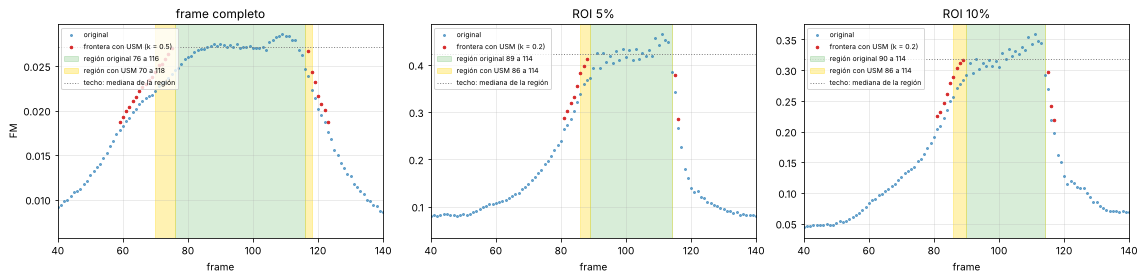

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, (nombre, (v, r, rec)) in zip(ax, experimentos.items()):
    u = usm_res[nombre]
    ru = u["region"]
    a.plot(v, ".", ms=4, color="tab:blue", alpha=0.6, label="original")
    a.plot(u["frontera"], u["fm"][u["frontera"]], ".", ms=5, color="tab:red", label=f"frontera con USM (k = {u['k']})")
    a.axvspan(r["inicio"], r["fin"], color="tab:green", alpha=0.18, label=f"región original {r['inicio']} a {r['fin']}")
    a.axvspan(ru["inicio"], r["inicio"], color="gold", alpha=0.3, label=f"región con USM {ru['inicio']} a {ru['fin']}")
    a.axvspan(r["fin"], ru["fin"], color="gold", alpha=0.3)
    a.axhline(u["techo"], color="gray", ls=":", lw=1, label="techo: mediana de la región")
    a.set_xlim(40, 140)
    a.set_title(nombre)
    a.set_xlabel("frame")
    a.grid(alpha=0.3)
    a.legend(fontsize=7, loc="upper left")
ax[0].set_ylabel("FM")
fig.tight_layout()
fig.savefig(FIGURAS / "extra_usm_curvas.png", dpi=100, bbox_inches="tight")
plt.show()

**Figura 12.** FM original (azul) y FM de los frames de frontera después del unsharp masking (rojo) en los tres experimentos. En verde, la región original; en amarillo, los frames que se suman a la región. La línea punteada es el techo que no pueden superar los frames procesados.

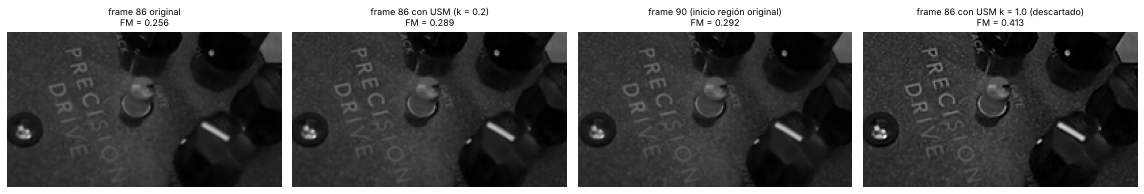

In [21]:
# antes y después en la ROI del 10%: frame de frontera procesado frente a un frame de la región original
y0, y1, x0, x1 = rois[0.10]
u = usm_res["ROI 10%"]
t = u["region"]["inicio"]
ref = r_roi[0.10]["inicio"]
paneles = [("frame %d original" % t, grises[t][y0:y1, x0:x1]),
           ("frame %d con USM (k = %.1f)" % (t, u["k"]), np.clip(unsharp(grises[t][y0:y1, x0:x1], 1.0, u["k"]), 0, 255)),
           ("frame %d (inicio región original)" % ref, grises[ref][y0:y1, x0:x1]),
           ("frame %d con USM k = 1.0 (descartado)" % t, np.clip(unsharp(grises[t][y0:y1, x0:x1], 1.0, 1.0), 0, 255))]
fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
for a, (titulo, img) in zip(ax, paneles):
    a.imshow(img, cmap="gray", vmin=0, vmax=255)
    a.set_title(f"{titulo}\nFM = {fm(img):.3f}", fontsize=9)
    a.axis("off")
fig.tight_layout()
fig.savefig(FIGURAS / "extra_usm_recortes.png", dpi=100, bbox_inches="tight")
plt.show()

**Figura 13.** Recortes de la ROI del 10%: el frame 86 original, el mismo frame con unsharp masking de ganancia 0,2, el frame 90 (inicio de la región original) como referencia y el frame 86 con ganancia 1,0. Con 0,2 el frame procesado se parece al de referencia. Con 1,0 su métrica supera al máximo real del video: es el artefacto que evitamos.

Para devolver el resultado generamos el video con los frames de frontera procesados. El unsharp masking se aplica al canal de luminancia (L de Lab), así se realza el detalle sin alterar el color. Usamos la ganancia elegida para la ROI del 10%.

In [22]:
def unsharp_color(bgr, sigma, k):
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
    lab[..., 0] = np.clip(unsharp(lab[..., 0], sigma, k), 0, 255).astype(np.uint8)
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)


u = usm_res["ROI 10%"]
salida = SALIDAS / "focus_video_usm.mp4"
escritor = cv2.VideoWriter(str(salida), cv2.VideoWriter_fourcc(*"mp4v"), FPS, (ANCHO, ALTO))
frontera = set(u["frontera"])
for t, f in enumerate(frames_bgr):
    escritor.write(unsharp_color(f, 1.0, u["k"]) if t in frontera else f)
escritor.release()
print(f"{salida}: {N} frames, {len(frontera)} procesados con unsharp masking (k = {u['k']})")
print("Región de máximo enfoque devuelta (ROI 10%):", {k: u['region'][k] for k in ('inicio', 'pico', 'fin')})

salidas/focus_video_usm.mp4: 171 frames, 12 procesados con unsharp masking (k = 0.2)
Región de máximo enfoque devuelta (ROI 10%): {'inicio': 86, 'pico': 111, 'fin': 114}


Con estas reglas (Tabla 4), la ganancia admitida es k = 0,5 para el frame completo y k = 0,2 para las dos ROI, con como máximo un 0,1% de píxeles saturados. La región se ensancha de 76 a 116 a 70 a 118 en el frame completo (8 frames más), de 89 a 114 a 86 a 114 en la ROI del 5% y de 90 a 114 a 86 a 114 en la ROI del 10%. Ningún frame procesado supera la mediana de los frames realmente enfocados, como se ve en la Figura 12.

Casi toda la expansión ocurre del lado izquierdo, y tiene sentido. La subida es gradual: los frames 84 a 89 están apenas por debajo del umbral y a simple vista ya se ven casi nítidos, así que alcanza con un realce leve. La bajada, en cambio, es abrupta. Después del frame 116 se pierde demasiada información de alta frecuencia, y llevar esos frames al umbral exigiría ganancias que violan las reglas. Coincide con lo que se dijo en clase: si una imagen está muy desenfocada, no se puede reconstruir sin inventar.

En los recortes de la Figura 13, el frame 86 procesado con k = 0,2 queda con una FM de 0,289, casi igual a la del frame 90 (0,292), y a la vista son comparables. Con k = 1,0 la FM sube a 0,413 y supera al máximo real del video (0,359), porque la métrica cuenta como detalle el grano de la superficie y el ruido de compresión amplificados. Ese es el artefacto que las reglas evitan.

Tampoco aplicamos el filtro a los frames que ya están dentro de la región. El objetivo del punto extra es recuperar la zona de transición, no modificar frames que el detector ya considera enfocados. Si los realzáramos, el ensanche dejaría de poder atribuirse al tratamiento de la frontera.

El control lo confirma (Tabla 5). Con el unsharp masking aplicado a todos los frames y la curva normalizada de nuevo, la región queda prácticamente igual: 89 a 114 en las dos ROI y 78 a 115 en el frame completo. Toda la curva sube y su forma relativa casi no cambia. La región se amplía solo cuando la frontera se trata en forma diferenciada, que es lo que pide la consigna.

Como resultado devolvemos la región ampliada y el video `salidas/focus_video_usm.mp4`, en el que solo están procesados los 12 frames de frontera de la ROI del 10%.

## 8. Detector automático completo

La función siguiente reúne todo el proceso: recibe la ruta de un video y, opcionalmente, la fracción de área de una ROI central, y devuelve la curva de la métrica, el frame de máximo enfoque y la región de máximo enfoque en frames y en segundos.

In [23]:
def detectar_maximo_enfoque(ruta_video, roi=None, umbral=UMBRAL):
    # roi: None para el frame completo, o la fracción del área de una ROI central (por ejemplo 0.05 o 0.10)
    cap = cv2.VideoCapture(str(ruta_video))
    if not cap.isOpened():
        raise FileNotFoundError(f"No se pudo abrir {ruta_video}")
    fps = cap.get(cv2.CAP_PROP_FPS)
    curva = []
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        g = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        if roi is not None:
            y0, y1, x0, x1 = roi_central(roi, *g.shape)
            g = g[y0:y1, x0:x1]
        curva.append(fm(g))
    cap.release()
    curva = np.array(curva)
    r = detectar_region(curva, umbral=umbral, fps=fps)
    return {"curva": curva, "frame_pico": r["pico"], "region_frames": (r["inicio"], r["fin"]),
            "region_segundos": (round(r["t_inicio"], 2), round(r["t_fin"], 2))}


for nombre, roi in (("frame completo", None), ("ROI 5%", 0.05), ("ROI 10%", 0.10)):
    d = detectar_maximo_enfoque(VIDEO, roi)
    print(f"{nombre:<16} pico: frame {d['frame_pico']:>3}   región: frames {d['region_frames'][0]} a {d['region_frames'][1]}"
          f"   ({d['region_segundos'][0]:.2f} a {d['region_segundos'][1]:.2f} s)")

frame completo   pico: frame 109   región: frames 76 a 116   (2.54 a 3.87 s)


ROI 5%           pico: frame 111   región: frames 89 a 114   (2.97 a 3.80 s)


ROI 10%          pico: frame 111   región: frames 90 a 114   (3.00 a 3.80 s)


**Tabla 6.** Salida de la función `detectar_maximo_enfoque` para los tres experimentos. Coincide con los resultados de las secciones 3 y 4, así que la función reproduce el proceso completo de punta a punta.

## Conclusiones

1. Implementamos la métrica FM de De y Masilamani siguiendo los seis pasos del paper. Para validarla desenfocamos un frame nítido con filtros gaussianos de sigma creciente: FM baja en forma monótona y los valores quedan en el mismo orden de magnitud que los publicados.
2. El detector no se queda con un único frame. Suaviza la curva, la normaliza entre su mínimo y su máximo y toma el intervalo contiguo al pico que supera el 80% del rango. Elegimos el umbral comparando con los frames a simple vista, y entre 0,7 y 0,85 la región cambia poco.
3. Con el frame completo la región va del frame 76 al 116 (pico en el 109). Con la ROI central del 5% va del 89 al 114 y con la del 10%, del 90 al 114, las dos con pico en el 111. La ROI da una detección más acotada y con el doble de rango dinámico, porque mide un solo objeto a una profundidad homogénea.
4. La matriz de enfoque reproduce la curva de referencia de la diapositiva y además muestra cómo el plano de foco recorre la escena: la parte superior se enfoca antes que el cuerpo del pedal.
5. Aplicamos unsharp masking solo a los frames de frontera, con una ganancia acotada para que ninguno supere a los frames realmente enfocados. En la ROI del 10% la región pasa de 90 a 114 a 86 a 114. Con el mismo filtro aplicado a todo el video la región no se ensancha, lo que muestra que el efecto viene del tratamiento de la frontera y no del filtro en sí.
6. Todo el proceso queda reunido en la función `detectar_maximo_enfoque`, que recibe la ruta del video y devuelve la curva, el frame de máximo enfoque y la región en frames y en segundos.